# Deep Learning Project 1 — executed experiment

Max Zhang (yz12020). This archived execution contains the 200-epoch RandAugment + Mixup run and two-view horizontal-flip probability TTA. Actual execution counts, logs and figures are retained; machine-specific output paths are redacted. Use reproduce.py for named presets. Historical training code and printed metrics are not replaced by results from new runs.

Model parameters: 2,797,610. Local validation: 95.34%. Latest author-confirmed Kaggle scores: public 84.30%, private 82.80%. The best visible submission instead uses RandAugment + flip TTA (public 84.80%, private 83.10%). These screenshot scores were reported after the competition deadline.


In [10]:
from pathlib import Path
import os, sys, json, random, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

IN_COLAB = False
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    pass
if IN_COLAB:
    drive.mount('/content/drive')

SMOKE_TEST = False
WIDTH = 32
EPOCHS = 200
BATCH_SIZE = 128
SEED = 42
NUM_WORKERS = 2 if IN_COLAB else 0
CACHE_IMAGES = True  # Decoded uint8 pixels in RAM; random transforms still run every access.
if IN_COLAB:
    ZIP_PATH = Path('/content/drive/MyDrive/data.zip')
    DATA_DIR = Path('/content/cifar_project_data')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/cifar_resnet_project')
else:
    candidates = [Path.cwd(), Path.cwd() / 'CIFAR10-ResNet',
                  Path.home() / 'Downloads' / 'CIFAR10-ResNet']
    PROJECT_DIR = next((p.resolve() for p in candidates
                        if (p / 'cifar_runtime.py').is_file()
                        and ((p / 'data.zip').is_file()
                             or (p / 'data' / 'train_labels.csv').is_file())), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError('Open the CIFAR10-ResNet project folder containing cifar_runtime.py and data.zip.')
    sys.path.insert(0, str(PROJECT_DIR))
    ZIP_PATH = PROJECT_DIR / 'data.zip'
    DATA_DIR = PROJECT_DIR / 'data'
    OUTPUT_ROOT = PROJECT_DIR / 'outputs'
from cifar_runtime import ImageDataset as CachedImageDataset, train_one_epoch, evaluate_model
RUN_NAME = 'resnet_width32_mix_200'
OUT = OUTPUT_ROOT / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if AMP:
    print('GPU:', torch.cuda.get_device_name(0))
elif IN_COLAB:
    raise RuntimeError('Enable a Colab GPU before training.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if AMP:
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

PyTorch: 2.11.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4080


## Load and verify the competition data
Expected files: `train_labels.csv`, `test.csv`, `sample_submission.csv`, `train_images/`, `test_images/`. No external dataset or pretrained weights are used.


Training images: 50000 | Competition test images: 2000
Class counts: {0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000, 9: 5000}
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1


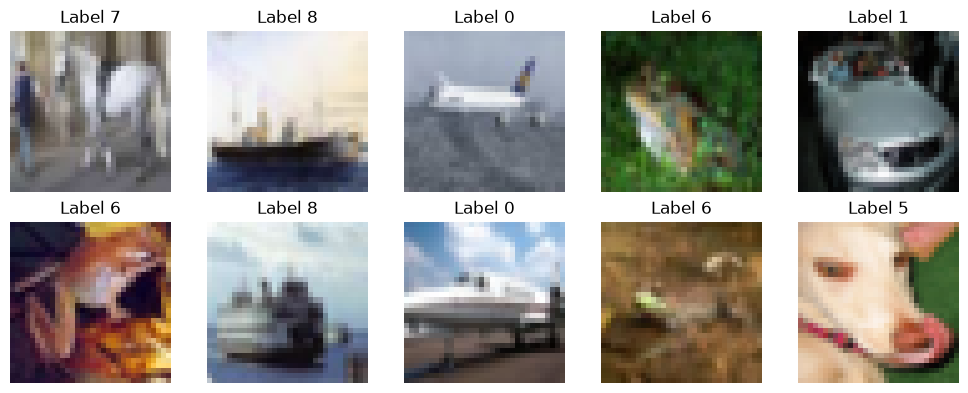

In [11]:
if not (DATA_DIR / 'train_labels.csv').exists():
    assert ZIP_PATH.exists(), f'Upload data.zip to {ZIP_PATH}'
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        for item in z.infolist():
            target = (DATA_DIR / item.filename).resolve()
            if not target.is_relative_to(DATA_DIR.resolve()):
                raise ValueError('Unsafe ZIP member')
        z.extractall(DATA_DIR)
train_df = pd.read_csv(DATA_DIR / 'train_labels.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
assert {'id','filename','label'} <= set(train_df.columns)
assert list(sample.columns) == ['id','label']
assert train_df['id'].is_unique and test_df['id'].is_unique
assert sorted(train_df.label.unique().tolist()) == list(range(10))
assert set(test_df.id) == set(sample.id)
for frame, folder in [(train_df, 'train_images'), (test_df, 'test_images')]:
    missing = [name for name in frame.filename if not (DATA_DIR / folder / name).is_file()]
    assert not missing, f'Missing images: {missing[:3]}'
print('Training images:', len(train_df), '| Competition test images:', len(test_df))
print('Class counts:', train_df.label.value_counts().sort_index().to_dict())
print(train_df.head())
fig, axes = plt.subplots(2, 5, figsize=(10,4))
for ax, (_, row) in zip(axes.flat, train_df.sample(10, random_state=SEED).iterrows()):
    img = Image.open(DATA_DIR / 'train_images' / row.filename)
    assert img.size == (32,32)
    ax.imshow(img); ax.set_title(f'Label {row.label}'); ax.axis('off')
plt.tight_layout(); plt.show()


## Fixed stratified validation split
Use 45,000 images for training and 5,000 for validation. Validation images receive no random augmentation. The competition test labels are unavailable; validation accuracy is not test accuracy.


In [12]:
train_idx, val_idx = train_test_split(np.arange(len(train_df)), test_size=0.1,
                                       random_state=SEED, stratify=train_df.label)
if SMOKE_TEST:
    train_idx = train_idx[:512]
    val_idx = val_idx[:256]
np.savez(OUT / 'split_indices.npz', train=train_idx, validation=val_idx)
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
class ImageDataset(CachedImageDataset):
    def __init__(self, frame, folder, transform, labeled=True):
        super().__init__(frame, folder, transform, labeled=labeled, cache_images=CACHE_IMAGES)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed); np.random.seed(worker_seed)
loader_rng = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(ImageDataset(train_df.iloc[train_idx], DATA_DIR/'train_images', train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=AMP, worker_init_fn=seed_worker, generator=loader_rng)
val_loader = DataLoader(ImageDataset(train_df.iloc[val_idx], DATA_DIR/'train_images', eval_transform),
                        batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=AMP)
print('Train:', len(train_idx), '| Validation:', len(val_idx))


Cached 45,000 images (131.8 MiB) in 5.8s; random augmentation remains per access.
Cached 5,000 images (14.6 MiB) in 0.6s; random augmentation remains per access.
Train: 45000 | Validation: 5000


## CIFAR-adapted ResNet
Four stages with two residual blocks each and channels `[w, 2w, 4w, 8w]`. A 3×3 stride-1 stem preserves small-image detail. Stage transitions use stride 2 and a 1×1 projection shortcut; global average pooling precedes the 10-class head. Width is the architecture variable in the proposed comparison.


In [13]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.shortcut = nn.Identity() if cin == cout and stride == 1 else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x): return self.relu(self.branch(x) + self.shortcut(x))

class SmallResNet(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3,width,3,padding=1,bias=False),
                                  nn.BatchNorm2d(width), nn.ReLU(inplace=True))
        blocks, cin = [], width
        for i, cout in enumerate([width,width*2,width*4,width*8]):
            blocks.extend([BasicBlock(cin,cout,1 if i==0 else 2), BasicBlock(cout,cout)])
            cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(cin,10)
        for m in self.modules():
            if isinstance(m,nn.Conv2d): nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')
            elif isinstance(m,nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self,x): return self.fc(self.pool(self.blocks(self.stem(x))).flatten(1))

model = SmallResNet(WIDTH).to(DEVICE)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert params <= 5_000_000
model.eval()
with torch.no_grad(): assert model(torch.zeros(2,3,32,32,device=DEVICE)).shape == (2,10)
print(model)
print(f'Trainable parameters: {params:,}')


SmallResNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (blocks): Sequential(
    (0): BasicBlock(
      (branch): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (shortcut): Identity()
      (relu): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (branch): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, tr

## Train and checkpoint
SGD with momentum, weight decay and cosine learning-rate decay. Mixed precision is enabled on CUDA. Both validation-selected `best.pt` and resumable `last.pt` are saved after epochs. Re-running with unchanged settings resumes automatically. For a new experiment, change the run name/settings folder instead of overwriting results. Training time depends on the GPU; the printed epoch time helps estimate it.


In [14]:
def train_one_epoch_mixup(
    model, loader, optimizer, scaler, criterion, device, amp
):
    model.train()
    total_loss, correct, total = 0.0, 0.0, 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        lam = np.random.beta(0.2, 0.2)
        index = torch.randperm(x.size(0), device=device)
        mixed_x = lam * x + (1 - lam) * x[index]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(mixed_x)
            loss = (
                lam * criterion(logits, y)
                + (1 - lam) * criterion(logits, y[index])
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(y)
        pred = logits.argmax(1)
        correct += (
            lam * (pred == y).sum().item()
            + (1 - lam) * (pred == y[index]).sum().item()
        )
        total += len(y)

    return total_loss / total, correct / total

In [15]:
actual_epochs = 1 if SMOKE_TEST else EPOCHS
config = dict(width=WIDTH, epochs=actual_epochs, batch_size=BATCH_SIZE, seed=SEED,
              smoke_test=SMOKE_TEST, trainable_parameters=params, lr=0.1,
              momentum=0.9, weight_decay=5e-4, train_size=len(train_idx), val_size=len(val_idx))
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=actual_epochs)
scaler = torch.amp.GradScaler('cuda', enabled=AMP)
criterion = nn.CrossEntropyLoss()

def evaluate(loader, collect_predictions=True):
    return evaluate_model(model, loader, criterion, DEVICE, AMP, collect_predictions)

history, start_epoch, best_acc = [], 0, -1.
last_path = OUT/'last.pt'
if last_path.exists():
    # Only load checkpoints created by this notebook in your own output folder.
    ckpt = torch.load(last_path, map_location=DEVICE, weights_only=False)
    assert ckpt['config'] == config, 'Configuration changed. Use a different RUN_NAME.'
    model.load_state_dict(ckpt['model']); optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler']); scaler.load_state_dict(ckpt['scaler'])
    history, start_epoch, best_acc = ckpt['history'], ckpt['epoch']+1, ckpt['best_acc']
    random.setstate(ckpt['python_rng']); np.random.set_state(ckpt['numpy_rng'])
    torch.set_rng_state(ckpt['torch_rng'].cpu()); loader_rng.set_state(ckpt['loader_rng'].cpu())
    if AMP: torch.cuda.set_rng_state_all([s.cpu() for s in ckpt['cuda_rng']])
    print('Resuming at epoch', start_epoch+1)
(OUT/'config.json').write_text(json.dumps(config, indent=2))

def atomic_save(payload, path):
    temp = path.with_suffix('.tmp')
    torch.save(payload,temp); os.replace(temp,path)

for epoch in range(start_epoch, actual_epochs):
    t0 = time.time()
    lr = optimizer.param_groups[0]['lr']
    train_loss, train_acc = train_one_epoch_mixup(
        model, train_loader, optimizer, scaler, criterion, DEVICE, AMP
    )
    val_loss,val_acc,_,_ = evaluate(val_loader, collect_predictions=False)
    scheduler.step()
    history.append(dict(epoch=epoch+1, train_loss=train_loss, train_accuracy=train_acc,
                        val_loss=val_loss, val_accuracy=val_acc, lr=lr, seconds=time.time()-t0))
    if val_acc > best_acc:
        best_acc = val_acc
        atomic_save(dict(model=model.state_dict(),config=config,epoch=epoch,best_acc=best_acc),OUT/'best.pt')
    payload = dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),
                   scaler=scaler.state_dict(),config=config,epoch=epoch,best_acc=best_acc,history=history,
                   python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),
                   loader_rng=loader_rng.get_state(),cuda_rng=torch.cuda.get_rng_state_all() if AMP else [])
    atomic_save(payload,last_path)
    pd.DataFrame(history).to_csv(OUT/'history.csv',index=False)
    print(f'Epoch {epoch+1:3d}/{actual_epochs} | train {train_acc:.2%} | val {val_acc:.2%} | {history[-1]["seconds"]:.1f}s',flush=True)
print('Finished. Outputs:',OUT)


Epoch   1/200 | train 25.63% | val 44.66% | 19.1s
Epoch   2/200 | train 40.35% | val 52.48% | 18.6s
Epoch   3/200 | train 49.76% | val 56.18% | 18.4s
Epoch   4/200 | train 57.05% | val 66.26% | 22.1s
Epoch   5/200 | train 59.63% | val 58.60% | 23.0s
Epoch   6/200 | train 63.20% | val 68.68% | 26.6s
Epoch   7/200 | train 63.89% | val 77.04% | 25.3s
Epoch   8/200 | train 66.20% | val 70.22% | 24.7s
Epoch   9/200 | train 66.62% | val 71.50% | 24.4s
Epoch  10/200 | train 67.68% | val 77.84% | 23.2s
Epoch  11/200 | train 68.01% | val 76.38% | 24.7s
Epoch  12/200 | train 69.07% | val 75.10% | 26.1s
Epoch  13/200 | train 68.66% | val 78.30% | 25.2s
Epoch  14/200 | train 67.44% | val 77.74% | 24.2s
Epoch  15/200 | train 68.96% | val 77.02% | 25.6s
Epoch  16/200 | train 70.38% | val 76.48% | 26.1s
Epoch  17/200 | train 70.37% | val 77.00% | 26.1s
Epoch  18/200 | train 70.19% | val 79.62% | 26.4s
Epoch  19/200 | train 70.33% | val 68.44% | 26.3s
Epoch  20/200 | train 70.18% | val 79.66% | 25.4s


## Evaluate the best checkpoint and save figures
Report this as **validation accuracy**. Obtain competition test accuracy from Kaggle only if scoring is available; otherwise state that test accuracy is unavailable.


FINAL EXPERIMENT
Best checkpoint epoch: 198
Validation accuracy: 95.3400%
Trainable parameters: 2,797,610
Competition test accuracy: unavailable locally (no test labels).


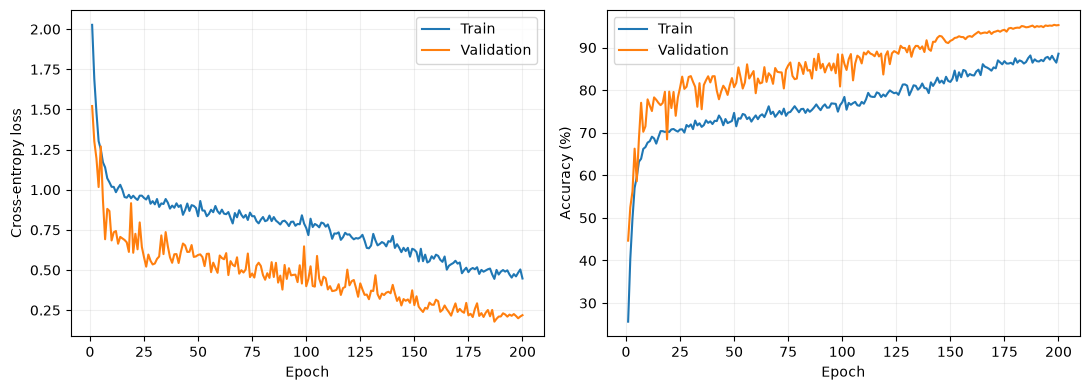

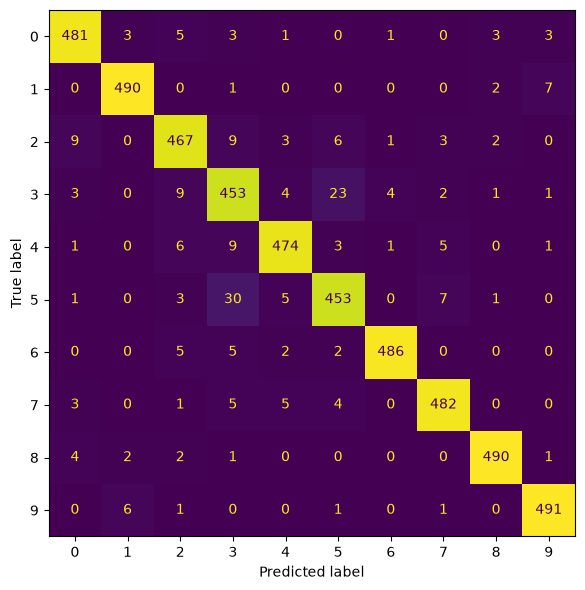

In [16]:
best = torch.load(OUT/'best.pt',map_location=DEVICE,weights_only=False)
model.load_state_dict(best['model'])
val_loss,val_acc,ys,preds = evaluate(val_loader)
print('SMOKE TEST ONLY' if SMOKE_TEST else 'FINAL EXPERIMENT')
print(f'Best checkpoint epoch: {best["epoch"]+1}')
print(f'Validation accuracy: {val_acc*100:.4f}%')
print(f'Trainable parameters: {params:,}')
print('Competition test accuracy: unavailable locally (no test labels).')
metrics = dict(validation_accuracy=val_acc,validation_loss=val_loss,trainable_parameters=params,
               best_epoch=best['epoch']+1,smoke_test=SMOKE_TEST,competition_test_accuracy=None)
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
h = pd.DataFrame(history)
fig,axes = plt.subplots(1,2,figsize=(11,4))
for col,label in [('train_loss','Train'),('val_loss','Validation')]: axes[0].plot(h.epoch,h[col],label=label)
for col,label in [('train_accuracy','Train'),('val_accuracy','Validation')]: axes[1].plot(h.epoch,h[col]*100,label=label)
axes[0].set_ylabel('Cross-entropy loss'); axes[1].set_ylabel('Accuracy (%)')
for ax in axes: ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'training_curves.png',dpi=160); plt.show()
fig,ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(ys,preds,labels=list(range(10))),display_labels=list(range(10))).plot(ax=ax,colorbar=False)
fig.tight_layout(); fig.savefig(OUT/'confusion_matrix.png',dpi=160); plt.show()


## Generate the Kaggle submission
One prediction per test ID, matched to the exact sample-submission order. This cell is blocked for a smoke test. No test labels are inferred or looked up externally.


In [17]:
if SMOKE_TEST:
    print('Skipped submission: set SMOKE_TEST=False and complete the actual training run first.')
else:
    test_loader = DataLoader(ImageDataset(test_df,DATA_DIR/'test_images',eval_transform,labeled=False),
                             batch_size=256,shuffle=False,num_workers=NUM_WORKERS,pin_memory=AMP)
    model.eval(); prediction_by_id = {}
    with torch.no_grad():
        for x,ids in test_loader:
            with torch.autocast(device_type=DEVICE.type,enabled=AMP):
                x = x.to(DEVICE, non_blocking=True)

                p_original = model(x).float().softmax(dim=1)
                p_flipped = model(torch.flip(x, dims=[3])).float().softmax(dim=1)

                logits = (p_original + p_flipped) / 2
            prediction_by_id.update(zip(ids.tolist(),logits.argmax(1).cpu().tolist()))
    submission = sample[['id']].copy()
    submission['label'] = submission.id.map(prediction_by_id)
    assert submission.label.notna().all() and len(submission)==len(test_df)
    submission['label'] = submission.label.astype(int)
    assert submission.label.between(0,9).all()
    assert submission.id.tolist()==sample.id.tolist()
    submission.to_csv(OUT/'submission.csv',index=False)
    print(submission.head()); print('Saved:',OUT/'submission.csv')


Cached 2,000 images (5.9 MiB) in 0.3s; random augmentation remains per access.
   id  label
0   0      6
1   1      3
2   2      3
3   3      1
4   4      3
Saved: <project-root>\outputs\resnet_width32_mix_200\submission.csv


## Compare actual experiments and prepare the report
Run this after completing both widths. The table only includes completed full runs. If only one was completed, report one; do not invent comparisons. Download the executed notebook from Colab so the repository includes outputs.

Report (maximum 8 pages): team names, public GitHub link on page 1, overview, methodology, architecture comparison, training settings, results and citations. Include the parameter count, training curves, actual validation accuracy, and Kaggle score if available. Explain the width/compute tradeoff using measured results.

Suggested repository: this executed notebook, a README with the data layout and run instructions, and small result files/figures. Do not commit the dataset. Keep your trained checkpoints available for reproduction.

References:
- He et al., *Deep Residual Learning for Image Recognition*: https://arxiv.org/abs/1512.03385
- PyTorch documentation: https://docs.pytorch.org/docs/stable/index.html
- Competition: https://www.kaggle.com/competitions/cifar-10-res-net-architecture-challenge-dl/overview

The model code here is self-contained. Cite any additional code or techniques you actually use.


In [18]:
rows=[]
for folder in sorted(OUTPUT_ROOT.glob('resnet_width*')):
    if not (folder/'metrics.json').exists(): continue
    m=json.loads((folder/'metrics.json').read_text())
    c=json.loads((folder/'config.json').read_text())
    if m['smoke_test']: continue
    log=pd.read_csv(folder/'history.csv')
    if len(log) != c['epochs']: continue
    rows.append(dict(run=folder.name,width=c['width'],parameters=m['trainable_parameters'],
                     epochs=c['epochs'],validation_accuracy_pct=100*m['validation_accuracy'],
                     training_minutes=log.seconds.sum()/60))
comparison=pd.DataFrame(rows)
print(comparison.to_string(index=False) if rows else 'No completed full experiments yet.')
if rows: comparison.to_csv(OUTPUT_ROOT/'experiment_comparison.csv',index=False)


                           run  width  parameters  epochs  validation_accuracy_pct  training_minutes
                resnet_width32     32     2797610     100                    94.04         28.120578
        resnet_width32_mix_200     32     2797610     200                    95.34         74.709453
resnet_width32_randaugment_200     32     2797610     200                    95.50         81.645155
